## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


- The point estimate of the ATE is -0.01. This means that the proportion of patients who received the invasive strategy (balloon pump) and survived was .01 less than the proportion of patients who received the conservative strategy and survived. This is shown in the code below where we isolate and compare the invasive and conservative survival rates. Therefore, because the conservative survival rate is just barely higher, I would rather receive the conservative strategy.

In [4]:
ISR = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean()
CSR = df.loc[ df['Group'] == 'Conservative', 'Survived'].mean()
print(f'Invasive Survival Rate: {ISR}')
print(f'Conservative Survival Rate: {CSR}')

Invasive Survival Rate: 0.2422680412371134
Conservative Survival Rate: 0.2519280205655527


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [5]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

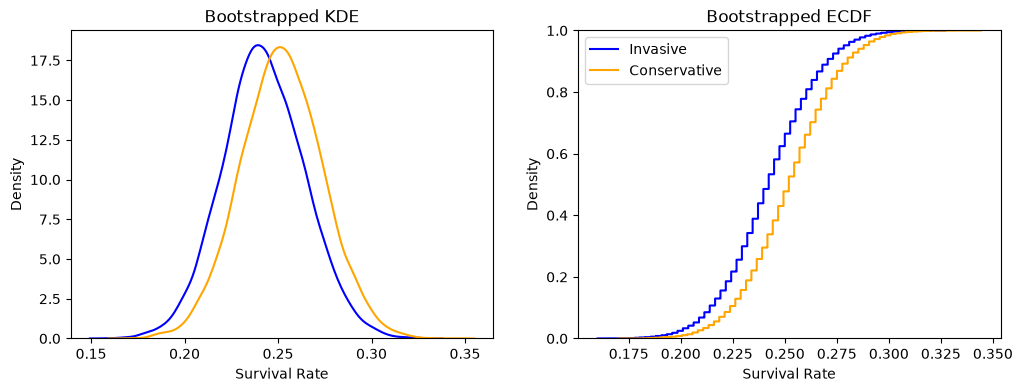

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

- The conservative strategy consistently preformed better in the bootstrap samples than the invasive procedure as seen in the bootstrap KDE and ECDF. These plots are showing the density (KDE) and distribution (ECDF) of the average survival rates across each 10,000 bootstrapped sample populations. In both the KDE and the ECDF, the conservative density is shifted to the right of the invasive density, showing that the sample population survival rate means are higher in the conservative population. It is particularly easy to see in the ECDF plot, as the conservative curve is to the right of the invasive curve at every quantile.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

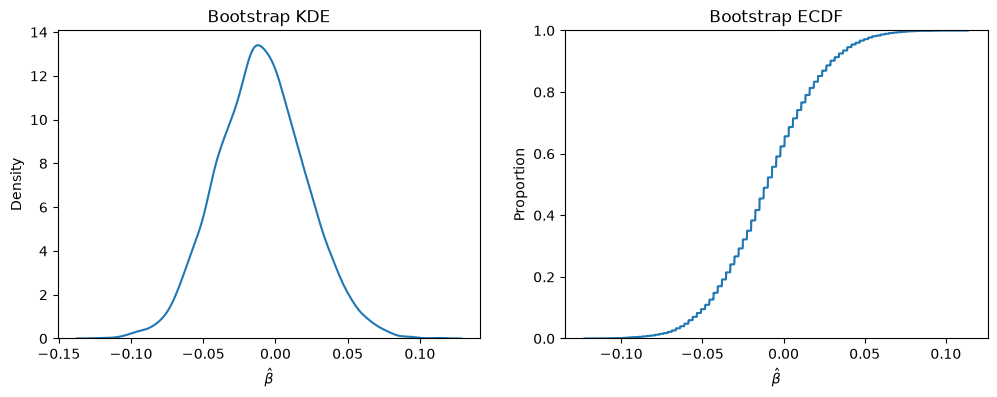

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


- Yes, the boostrap KDE of the ATE roughly has a bell shape. The ATE has a range of values from about -0.15 to 0.10, although the majority of ATE values fall around -0.01 (where the crest of the bell curve is).

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [8]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05860288  0.04183341]
95% CI: [-0.06882603  0.05211635]
99% CI: [-0.08946433  0.07270161]


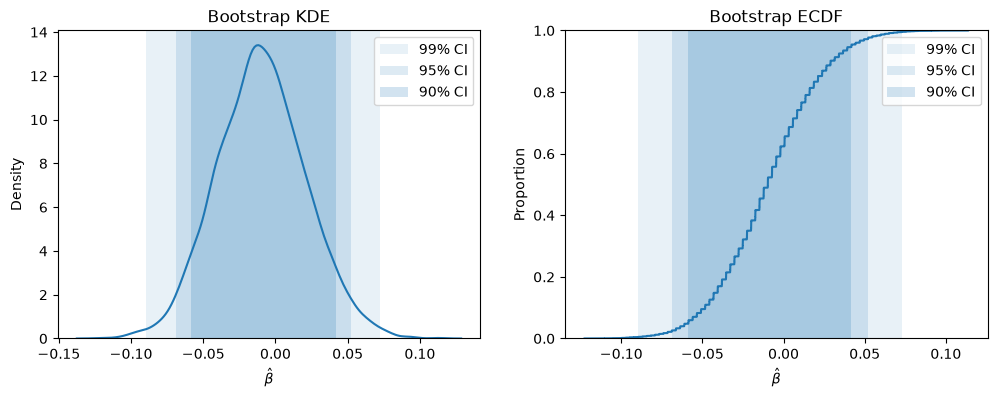

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

- We fail to reject the null hypothesis (that the effect size is 0) for each confidence interval (90%, 95% and 99%). A ATE value of 0 is firmly within each of these CIs and is actually close to right in the middle of each of them. It is easy to visualize this in the KDE/ECDF above as we can see the $\hat{\beta}$ value of 0.00 is well within each CIs blue shade.

In [10]:
ci50 = np.quantile(ate, [.25, .75])
print(f"50% CI: {ci50}")

50% CI: [-0.03027191  0.0109122 ]


- As shown above, we even fail to reject the null hypothesis at a ridiculous 50% CI

**6.** What have we learned about inserting balloons into hearts?

- We have learned that there is no evidence in the data to show that inserting balloons into hearts increases patient survival rate. In fact, even though we cannot claim the opposite (that the invasive strategy DECREASES patient survival rate compared to the conservative strategy), the data indicates that this is more likely than an increase. We can see below that for the boostrap ATEs, the median was -0.00965 and 61.08% of boostrap ATEs were negative (negative ATE indicating that the conservative strategy was more effective). However, because 0.00 is within each CI (even down to a 50% CI), we still cannot make the claim that the conservative strategy is more effective.

In [11]:
ate_median = np.median(ate)
proportion = np.mean(np.array(ate) < 0)
print(f"ATE Median: {ate_median}")
print(f"Proportion of ATE < 0: {proportion}")

ATE Median: -0.009673230328889837
Proportion of ATE < 0: 0.6238


# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

# 1)

In [12]:
df2 = pd.read_csv('./data/diabetes.csv') #Upload file as new df
df2['success'] = (df2['outcome'] == 'success').astype(float) #Create new column casting success as a float (1 = success, 0 = failure)
df2.drop(columns=['outcome', 'Unnamed: 0'], inplace=True) #Drop unnecessary columns
print(pd.crosstab( df2['treatment'], df2['success']), '\n') #Crosstab

#Avgs for all treatments
LSR = df2.loc[ df2['treatment'] == 'lifestyle', 'success'].mean()
MSR = df2.loc[ df2['treatment'] == 'met', 'success'].mean()
RSR = df2.loc[ df2['treatment'] == 'rosi', 'success'].mean()
print(f'Lifestyle Success Rate: {LSR}')
print(f'Metformin Success Rate: {MSR}')
print(f'Rosiglitazone Success Rate: {RSR}')


success    0.0  1.0
treatment          
lifestyle  109  125
met        120  112
rosi        90  143 

Lifestyle Success Rate: 0.5341880341880342
Metformin Success Rate: 0.4827586206896552
Rosiglitazone Success Rate: 0.6137339055793991


- Average outcomes listed above as treatment success rates

# 2)

In [13]:
## Bootstrapping:
R = 10_000

df2_l = df2.loc[ df2['treatment'] == 'lifestyle',:]
df2_m = df2.loc[ df2['treatment'] == 'met',:]
df2_r = df2.loc[ df2['treatment'] == 'rosi',:]

outcome_l = []
outcome_m = []
outcome_r = []
ate_lm = []
ate_lr = []
ate_mr = [] # Store computed effects

for t in range(R):
    ## Resample:
    df2_lt = df2_l.sample(frac=1.0, replace=True)
    df2_mt = df2_m.sample(frac=1.0, replace=True)
    df2_rt = df2_r.sample(frac=1.0, replace=True)


    ## Evaluate outcomes:
    olt = df2_lt['success'].mean() # Mean outcome for L
    omt = df2_mt['success'].mean() # Mean outcome for M
    ort = df2_rt['success'].mean() # Mean outcome for R

    ## Compute ATE:
    ate_lm_t = olt - omt # Compute ATE for L vs M
    ate_lr_t = olt - ort # Compute ATE for L vs R
    ate_mr_t = omt - ort # Compute ATE for M vs R

    ## Store results:
    outcome_l.append(olt) # Save new value
    outcome_m.append(omt) # Save new value
    outcome_r.append(ort) # Save new value
    ate_lm.append(ate_lm_t) # Save new value
    ate_lr.append(ate_lr_t) # Save new value
    ate_mr.append(ate_mr_t) # Save new value

# 3)

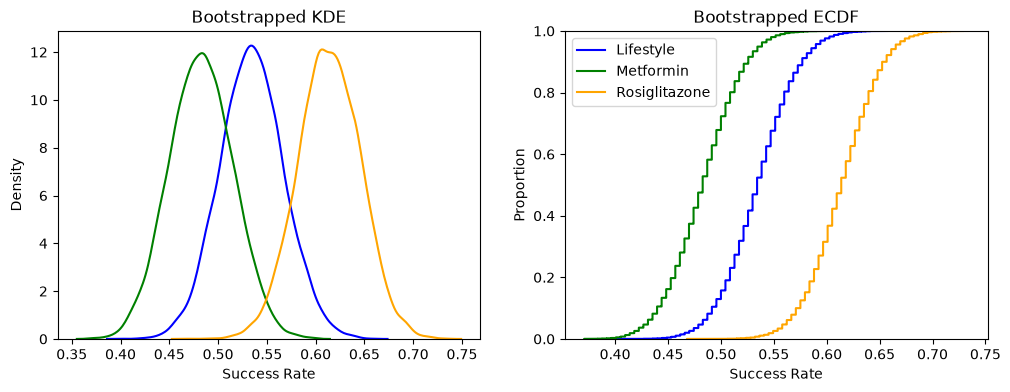

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_l, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_m, label='Metformin', color='green', ax=ax[0])
sns.kdeplot(outcome_r, label='Rosiglitazone', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_l, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_m, label='Metformin', color='green', ax=ax[1])
sns.ecdfplot(outcome_r, label='Rosiglitazone', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

- The visual pattern is pretty clear: Rosiglitazone generally has the highest success rate followed by lifestyle changes and then Metformin. We can see this in the plots as Rosiglitazone is shifted the furthest right in both the KDE and ECDF, followed by lifestyle changes and lastly Metformin. There is no intersection in any of the three ECDFs. All three also roughly have a bell shape and seem normally distributed.

# 4)

# L-M ATE:

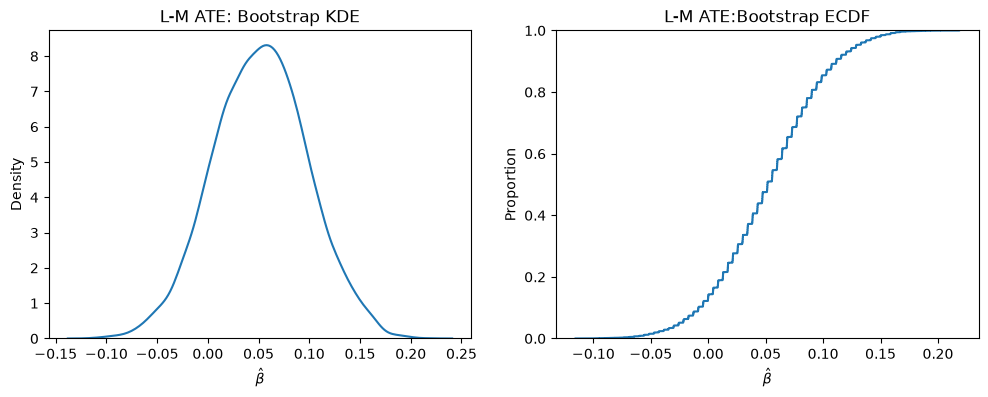

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_lm, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("L-M ATE: Bootstrap KDE")

## ECDF
sns.ecdfplot(ate_lm, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("L-M ATE:Bootstrap ECDF")

plt.show()

# L-R ATE:

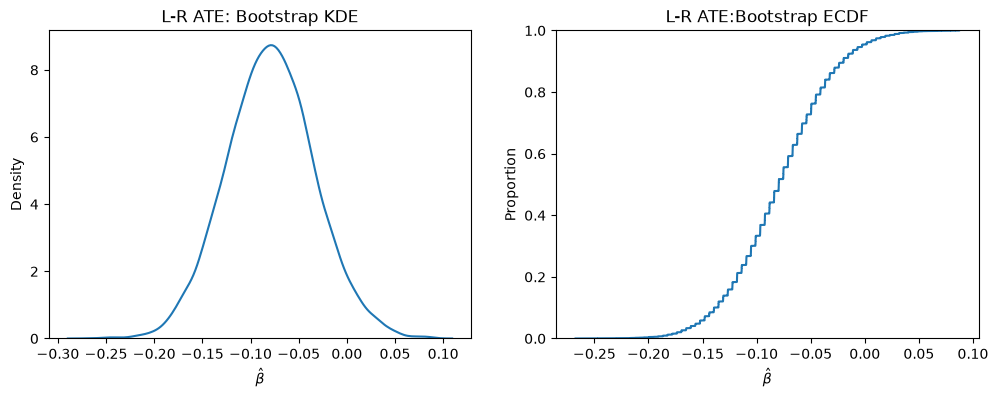

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_lr, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("L-R ATE: Bootstrap KDE")

## ECDF
sns.ecdfplot(ate_lr, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("L-R ATE:Bootstrap ECDF")

plt.show()

# M-R ATE:

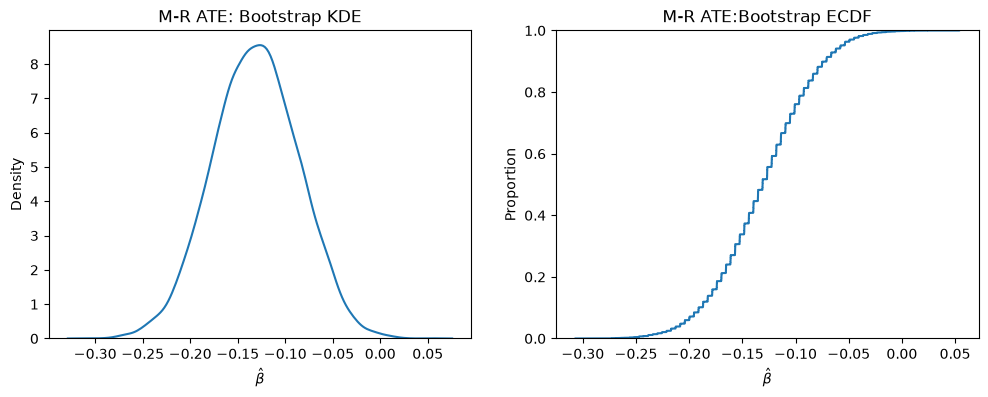

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_mr, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("M-R ATE: Bootstrap KDE")

## ECDF
sns.ecdfplot(ate_mr, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("M-R ATE:Bootstrap ECDF")

plt.show()

# 5)

In [18]:
LMci90 = np.quantile(ate_lm, [.05, .95])
LMci95 = np.quantile(ate_lm, [.025, .975])
LMci99 = np.quantile(ate_lm, [.005, .995])
LRci90 = np.quantile(ate_lr, [.05, .95])
LRci95 = np.quantile(ate_lr, [.025, .975])
LRci99 = np.quantile(ate_lr, [.005, .995])
MRci90 = np.quantile(ate_mr, [.05, .95])
MRci95 = np.quantile(ate_mr, [.025, .975])
MRci99 = np.quantile(ate_mr, [.005, .995])

print(f'L-M ATE CIs:\nL-M 90% CI: {LMci90}\nL-M 95% CI: {LMci95}\nL-M 99% CI: {LMci99}\n')
print(f'L-R ATE CIs:\nL-R 90% CI: {LRci90}\nL-R 95% CI: {LRci95}\nL-R 99% CI: {LRci99}\n')
print(f'M-R ATE CIs:\nM-R 90% CI: {MRci90}\nM-R 95% CI: {MRci95}\nM-R 99% CI: {MRci99}\n')


L-M ATE CIs:
L-M 90% CI: [-0.02560419  0.12875774]
L-M 95% CI: [-0.03883087  0.14519415]
L-M 99% CI: [-0.06848714  0.16718243]

L-R ATE CIs:
L-R 90% CI: [-0.1524348  -0.00247515]
L-R 95% CI: [-0.16943619  0.01450836]
L-R 99% CI: [-0.19515058  0.04455101]

M-R ATE CIs:
M-R 90% CI: [-0.20419565 -0.05775492]
M-R 95% CI: [-0.22110543 -0.04487938]
M-R 99% CI: [-0.2471881  -0.01491037]



- L-R is statistically significant at a 90% CI while M-R is statistically significant at every CI (90%, 95% and 99%). This is because 0.00 is not in any of these CIs. It seems like Rosiglitazone is the most effective as it had statistically significant ATEs against both of the other treatments (albeit it was only statistically significant against the lifestyle treatment at a 90% CI). The ATE values were negative as the comparison (subtracting the mean treatment success rates) was calculated with Rosiglitazone last, so a negative value indicates it was more effective.

# 6)

**Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.**

In the performed clinical trial, three different treatments were assigned to three random groups of pre-diabetics to reduce the progression to full diabetes: Metformin, Rosiglitazone, and lifestyle adjustments to diet and and exercise (for simplicity, we will refer to them as the M treatment, R treatment and L treatment respectively). Each subject's success was measured on a simple binary success metric (1 for success, 0 for failure). The trial outcome's initial analysis focused on the success rate for each individual treatment, displayed in the table below:
| Treatment | Success Rate|
| --- | --- |
| Lifestyle | 0.5341880341880342 |
| Metformin | 0.4827586206896552 |
| Rosiglitazone | 0.6137339055793991 |

However, to ensure more robust results, each individual treatment was bootstrapped to create 10,000 different plausible sample populations and thus 10,000 different success rates for each treatment group. KDE and ECDF plots were then created from these results and overlaid atop one another for visual analysis:

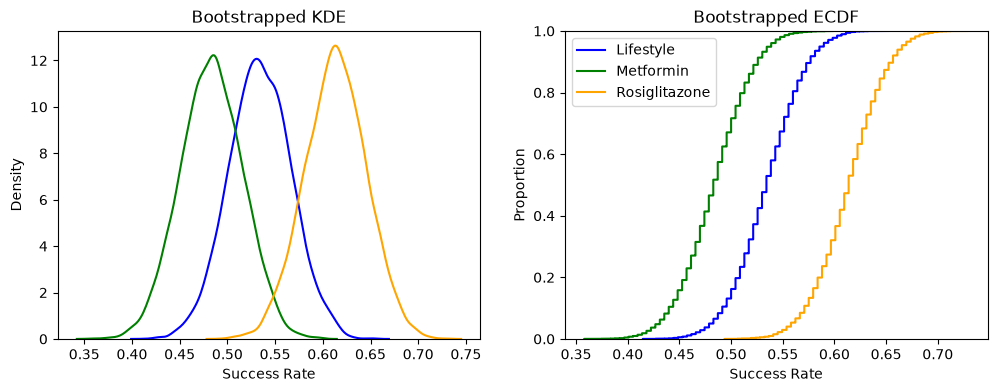

Both the KDE and ECDF plots show a clear pattern that mimics the initial treatment group success rates: the R treatment was the most effective followed by L and M in that order. The plots follow this order from right to left (higher success rates to lower) and all look roughly normal. Another thing to note is that we can also see that the R treatment is set further apart from the other two treatments while L and M seem grouped closer. While these visual observations are helpful, we need direct quantitative comparisons between the treatment groups to gather more concrete results.      

In order to do this, we take the ATEs between each treatment group and the two others to quantify the difference in their treatment results. Because we are doing this across each 10,000 bootstrap samples per treatment group, we can look at the density and distribution of these 10,000 ATE values for each comparison using KDEs and ECDFs. The ATE results are highlighted in the plots below:

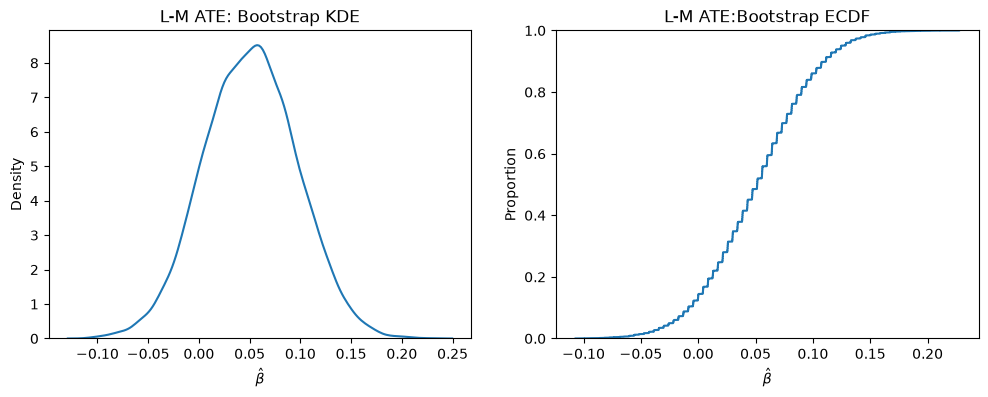

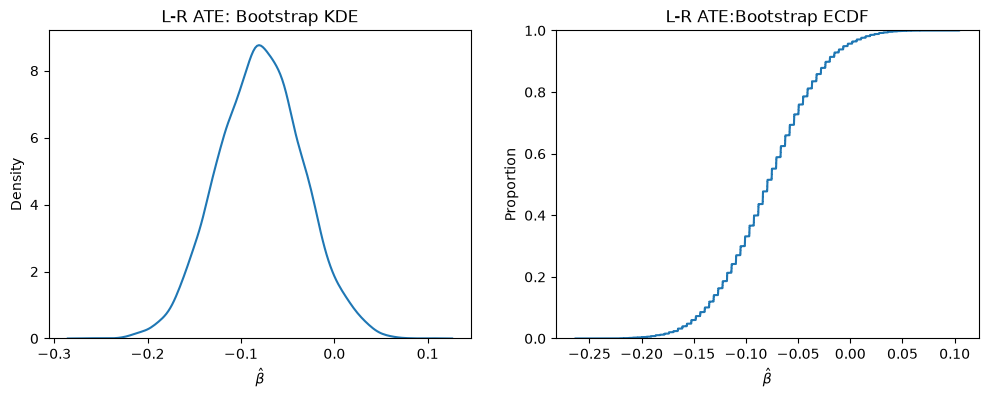

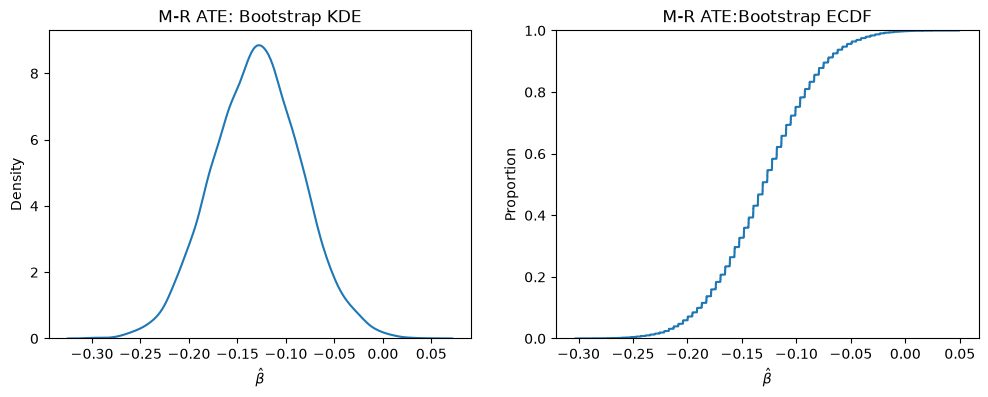

These visuals reinforce our intuition from the first KDE and ECDFs. Based on the density crests, R seems to outperform both M and L and L seems to outperform M. However, for there to be statistical significance we need to create confidence intervals to show that a treatment outperformed another in a high percentage of the ATEs. Our analysis focused on confidence intervals of 90, 95 and 99 with the results below: 

| Treatment ATE | 90% CI | 95% CI | 99% CI |
| --- | --- | --- | --- |
| L-M | [-0.02188329,  0.12470528] | [-0.03864574,  0.14146773] | [-0.06874484,  0.1674405 ] |
| L-R | <span style="color:green">[-0.15241646, -0.00262188]</span> | [-0.1653461,   0.01043615] | [-0.19522413,  0.03609561] |
| M-R | <span style="color:green">[-0.20417715, -0.05361107]</span> | <span style="color:green">[-0.21710865, -0.04051308]</span> | <span style="color:green">[-0.24728226, -0.01054444]</span> |

The statistically significant results are highlighted in green. These are CIs that do not include 0 in their range and can reject the null hypothesis that there is no difference in treatment effects. R outperformed M in 99% (and 95 and 90) of instances so we can say with a lot of confidence that it is a more effective treatment than M. R outperformed L in 90% of instances but not 95 or 99, so while it likely is more effective, we cannot claim its effectiveness over L with the same degree of confidence as we can over M. Lastly, all of the CIs for L-M included 0 so none of them were statistically significant and we cannot confidently claim that L is more effective than M despite what we saw in the previous plots. However, just because we cannot "confidently" make this claim, the data still suggests that L may be more effective, as using the ECDF plot where $\hat{\beta}$ > 0 we can see that L outperformed M in 86.35% instances.